In [1]:
import pandas as pd
import glob

# Path to all CSVs (adjust this to your Kaggle download folder)
path = "./CICIDS2017/"  

# Load all CSV files into a list
all_files = glob.glob(path + "*.csv")

# Combine into one DataFrame
df_list = [pd.read_csv(file) for file in all_files]
df = pd.concat(df_list, ignore_index=True)
df = df.sample(n=20000, random_state=42)

print("Combined shape:", df.shape)
print("Columns:", df.columns[:10], "...")
print("Unique labels:", df[' Label'].unique())

Combined shape: (20000, 79)
Columns: Index([' Destination Port', ' Flow Duration', ' Total Fwd Packets',
       ' Total Backward Packets', 'Total Length of Fwd Packets',
       ' Total Length of Bwd Packets', ' Fwd Packet Length Max',
       ' Fwd Packet Length Min', ' Fwd Packet Length Mean',
       ' Fwd Packet Length Std'],
      dtype='object') ...
Unique labels: ['BENIGN' 'DoS Hulk' 'PortScan' 'DDoS' 'DoS slowloris' 'DoS GoldenEye'
 'FTP-Patator' 'DoS Slowhttptest' 'Bot' 'SSH-Patator' 'Web Attack � XSS'
 'Web Attack � Brute Force' 'Infiltration']


In [2]:
import pandas as pd
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from scipy.stats import mode
import time
import os
from joblib import dump, load
import os
from scipy.stats import mode
from tqdm import tqdm
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.optim as optim
    

SEED = 42
NUM_FEATURES = 13

In [3]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

# Strip spaces from column names
df.columns = df.columns.str.strip()

df['Label'] = df['Label'].apply(lambda x: 0 if x.strip() == "BENIGN" else 1)

print("Unique labels after mapping:", df['Label'].unique())
print(df['Label'].value_counts())

feature_names = df.columns
# Separate features/labels
X = df.drop('Label', axis=1)
y = df['Label']


# Train/test split
SEED = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Original class distribution (train): {np.bincount(y_train)}")

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=NUM_FEATURES, random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test_scaled)

print("Features Selected: ")
for i, component in enumerate(pca.components_):
    important_idx = np.argmax(np.abs(component))
    print(f"Principal Component {i+1}: most important feature is '{feature_names[important_idx]}'")


X_train = X_train_pca
X_test = X_test_pca

print(X_train.shape, X_test.shape)

Unique labels after mapping: [0 1]
Label
0    16085
1     3893
Name: count, dtype: int64
Original class distribution (train): [12867  3115]
Features Selected: 
Principal Component 1: most important feature is 'Flow IAT Max'
Principal Component 2: most important feature is 'Total Backward Packets'
Principal Component 3: most important feature is 'Fwd IAT Min'
Principal Component 4: most important feature is 'Avg Fwd Segment Size'
Principal Component 5: most important feature is 'min_seg_size_forward'
Principal Component 6: most important feature is 'ACK Flag Count'
Principal Component 7: most important feature is 'Active Max'
Principal Component 8: most important feature is 'Fwd IAT Min'
Principal Component 9: most important feature is 'Active Mean'
Principal Component 10: most important feature is 'URG Flag Count'
Principal Component 11: most important feature is 'RST Flag Count'
Principal Component 12: most important feature is 'Fwd URG Flags'
Principal Component 13: most important fe

In [4]:
def create_sequential_batches(X_train, y_train, X_test, y_test, train_batch_size=300, test_batch_size=100):
    train_batches = []
    test_batches = []
    num_batches = min(len(X_train) // train_batch_size, len(X_test) // test_batch_size)
    for i in range(num_batches):
        train_start = i * train_batch_size
        train_end = train_start + train_batch_size
        test_start = i * test_batch_size
        test_end = test_start + test_batch_size
        train_batches.append((X_train[train_start:train_end], y_train[train_start:train_end]))
        test_batches.append((X_test[test_start:test_end], y_test[test_start:test_end]))
    return train_batches, test_batches

# Usage:
train_batches, test_batches = create_sequential_batches(X_train, y_train, X_test, y_test)

In [5]:
SEED = 42
# NUM_FEATURES = 4
TRAIN_BATCH_SIZE = 300
TEST_BATCH_SIZE = 100
NUM_BATCHES = 10

from joblib import Parallel, delayed


dev = qml.device("default.qubit", wires=NUM_FEATURES)

@qml.qnode(dev)
def kernel_circuit(x1, x2):
    qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(NUM_FEATURES))
    return qml.probs(wires=range(NUM_FEATURES))

def kernel(x1, x2):
    return kernel_circuit(x1, x2)

def compute_kernel_matrix(X1, X2):
    n_samples_1, n_samples_2 = len(X1), len(X2)
    kernel_matrix = np.zeros((n_samples_1, n_samples_2))
    for i in range(n_samples_1):
        for j in range(n_samples_2):
            probs = kernel_circuit(X1[i], X2[j])
            kernel_matrix[i, j] = probs[0]  # this represents the inner product now
    return kernel_matrix

In [6]:
from sklearn.model_selection import GridSearchCV

# Store metrics
all_test_preds = []
all_test_labels = []
train_accuracies = []
test_accuracies = []


for batch_idx in range(10):
    print(f"\nBatch {batch_idx + 1}/10")

    # Get batch data
    X_batch_train, y_batch_train = train_batches[batch_idx]
    X_batch_test, y_batch_test = test_batches[batch_idx]

    print("- Computing training kernel...")
    K_train = compute_kernel_matrix(X_batch_train, X_batch_train)

    print("- Computing testing kernel...")
    K_test = compute_kernel_matrix(X_batch_test, X_batch_train)

    if batch_idx == 4:
        K_train_4 = K_train
        K_test_4 = K_test

    # Hyperparameter tuning for C
    print("- Tuning C value...")
    param_grid = {"C": [0.1, 1, 10, 20, 30, 40, 50, 60]}
    grid = GridSearchCV(SVC(kernel='precomputed'), param_grid, cv=3)
    grid.fit(K_train, y_batch_train)
    best_model = grid.best_estimator_
    print(f"- Best C: {grid.best_params_['C']}")


    # Predictions
    y_pred = best_model.predict(K_test)
    all_test_preds.append(y_pred)
    all_test_labels.append(y_batch_test)

    # Overfitting check
    train_preds = best_model.predict(K_train)
    train_acc = accuracy_score(y_batch_train, train_preds)
    test_acc = accuracy_score(y_batch_test, y_pred)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"- Train Accuracy: {train_acc:.4f}")
    print(f"- Test Accuracy: {test_acc:.4f}")
    if train_acc - test_acc > 0.10:
        print("- Possible overfitting detected (Train >> Test)")



Batch 1/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 20
- Train Accuracy: 0.9600
- Test Accuracy: 0.9100

Batch 2/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 1
- Train Accuracy: 0.9667
- Test Accuracy: 0.8700

Batch 3/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 10
- Train Accuracy: 0.9667
- Test Accuracy: 0.9100

Batch 4/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 40
- Train Accuracy: 0.9700
- Test Accuracy: 0.9300

Batch 5/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 50
- Train Accuracy: 0.9833
- Test Accuracy: 0.9000

Batch 6/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 10
- Train Accuracy: 0.9633
- Test Accuracy: 0.9100

Batch 7/10
- Computing training kernel...
- Computing testing kernel..

Text(0.5, 1.0, 'Quantum Kernel Train Matrix')

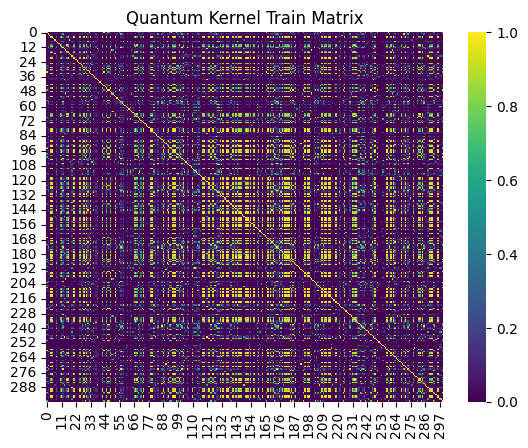

In [7]:
sns.heatmap(K_train_4, cmap="viridis")
plt.title("Quantum Kernel Train Matrix")

Text(0.5, 1.0, 'Quantum Kernel Test Matrix')

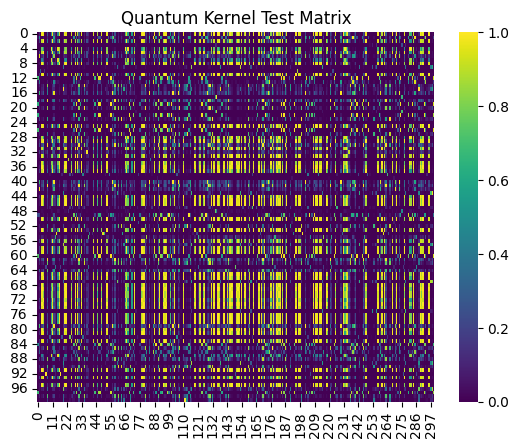

In [8]:
sns.heatmap(K_test_4, cmap="viridis")
plt.title("Quantum Kernel Test Matrix")


Final Batched QSVM Accuracy: 0.9010
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.95      0.94       805
           1       0.76      0.71      0.74       195

    accuracy                           0.90      1000
   macro avg       0.85      0.83      0.84      1000
weighted avg       0.90      0.90      0.90      1000



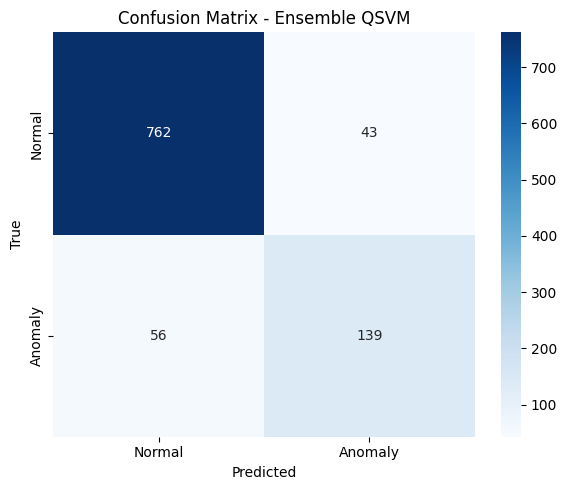

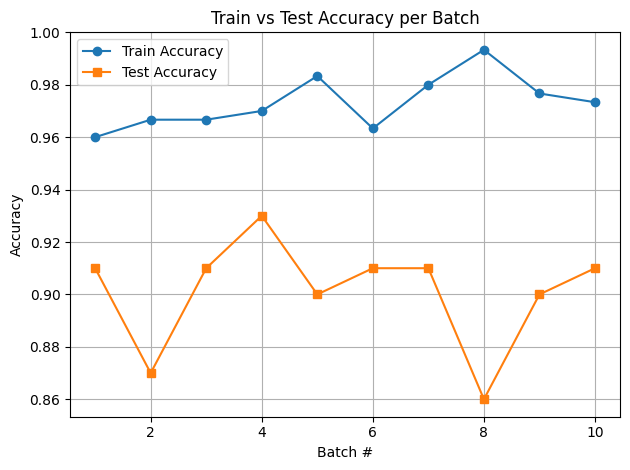

In [9]:
# Final evaluation
all_test_preds = np.concatenate(all_test_preds)
all_test_labels = np.concatenate(all_test_labels)

final_acc = accuracy_score(all_test_labels, all_test_preds)
print(f"\nFinal Batched QSVM Accuracy: {final_acc:.4f}")
print("Classification Report:\n", classification_report(all_test_labels, all_test_preds))

# Confusion matrix
cm = confusion_matrix(all_test_labels, all_test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.title("Confusion Matrix - Ensemble QSVM")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# Plot train vs test accuracy
plt.plot(range(1, 11), train_accuracies, label="Train Accuracy", marker='o')
plt.plot(range(1, 11), test_accuracies, label="Test Accuracy", marker='s')
plt.title("Train vs Test Accuracy per Batch")
plt.xlabel("Batch #")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [10]:
import numpy as np

def compute_kta(kernel_matrix, labels):
    """
    Compute Kernel Target Alignment (KTA).
    :param kernel_matrix: (n x n) kernel matrix (usually training)
    :param labels: (n,) label vector
    :return: alignment score (float)
    """
    # Convert labels to +1 / -1
    y = np.where(labels == 1, 1, -1)
    target_matrix = np.outer(y, y)

    # Frobenius inner product
    numerator = np.sum(kernel_matrix * target_matrix)
    denominator = np.linalg.norm(kernel_matrix, 'fro') * np.linalg.norm(target_matrix, 'fro')

    return numerator / denominator


In [11]:
n_layers = 5


def qnn_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(NUM_FEATURES))
    qml.StronglyEntanglingLayers(weights, wires=range(NUM_FEATURES))
    return [qml.expval(qml.PauliZ(i)) for i in range(NUM_FEATURES)]

qnode = qml.QNode(qnn_circuit, dev, interface="torch")

class QNNClassifier(nn.Module):
    def __init__(self, n_layers, n_qubits):
        super().__init__()
        weight_shapes = {"weights": (n_layers, n_qubits, 3)}
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.fc = nn.Linear(n_qubits, 1)
    
    def forward(self, x):
        x = self.qlayer(x)
        x = self.fc(x)
        return x  # No sigmoid here

<generator object Module.parameters at 0x7f078f70aea0>
Epoch 10/100, Loss: 0.2271
Epoch 20/100, Loss: 0.1845
Epoch 30/100, Loss: 0.1704
Epoch 40/100, Loss: 0.1564
Epoch 50/100, Loss: 0.1538
Epoch 60/100, Loss: 0.1417
Epoch 70/100, Loss: 0.1359
Epoch 80/100, Loss: 0.1328
Epoch 90/100, Loss: 0.1281
Epoch 100/100, Loss: 0.1268
QNN Accuracy on Test Data: 0.9290
Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.97      0.96       805
           1       0.84      0.78      0.81       195

    accuracy                           0.93      1000
   macro avg       0.90      0.87      0.88      1000
weighted avg       0.93      0.93      0.93      1000



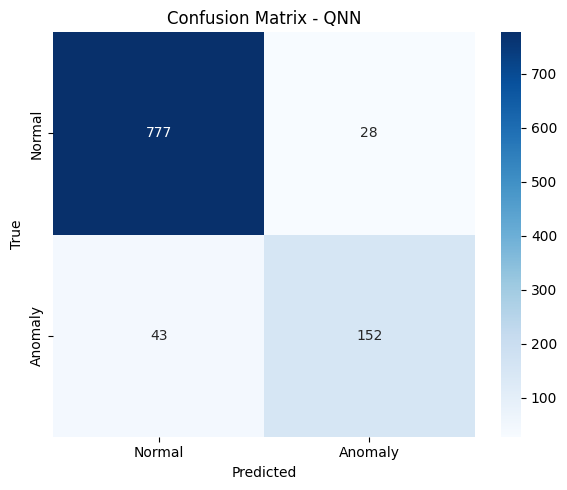

In [12]:
X_train_300 = X_train[:3000]
X_test_100 = X_test[:1000]
y_train_300 = y_train[:3000]
y_test_100 = y_test[:1000]

loss_values = []

# Prepare data
X_train_tensor = torch.tensor(X_train_300, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_300.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_100, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_100.values, dtype=torch.float32).unsqueeze(1)

# Use DataLoader for mini-batch training
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Model, loss, optimizer
model = QNNClassifier(n_layers=n_layers, n_qubits=NUM_FEATURES)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)
print(model.parameters())

# Training loop
epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    epoch_loss = running_loss / len(train_loader)
    loss_values.append(epoch_loss)
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

# Evaluation
model.eval()
# with torch.no_grad():
#     y_pred_logits = model(X_test_tensor)
#     qnn_preds = (torch.sigmoid(y_pred_logits) > 0.5).int().squeeze().numpy()

with torch.no_grad():
    y_pred_logits = model(X_test_tensor)  # shape: (N, 1)
    qnn_sigmoid = torch.sigmoid(y_pred_logits).squeeze()  # shape: (N,)
    qnn_preds = (qnn_sigmoid > 0.5).int().numpy()

    # Convert to probability distribution over 2 classes: [P(class 0), P(class 1)]
    qnn_probs = torch.stack([1 - qnn_sigmoid, qnn_sigmoid], dim=1).cpu().numpy()  # shape: (N, 2)


accuracy_qnn = accuracy_score(y_test_100, qnn_preds)
print(f"QNN Accuracy on Test Data: {accuracy_qnn:.4f}")

print("Classification Report:\n", classification_report(y_test_100, qnn_preds))

cm = confusion_matrix(y_test_100, qnn_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.title("Confusion Matrix - QNN")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [13]:
from joblib import dump, load

dump(model, 'final_model(13  qnn).joblib')



['final_model(13  qnn).joblib']

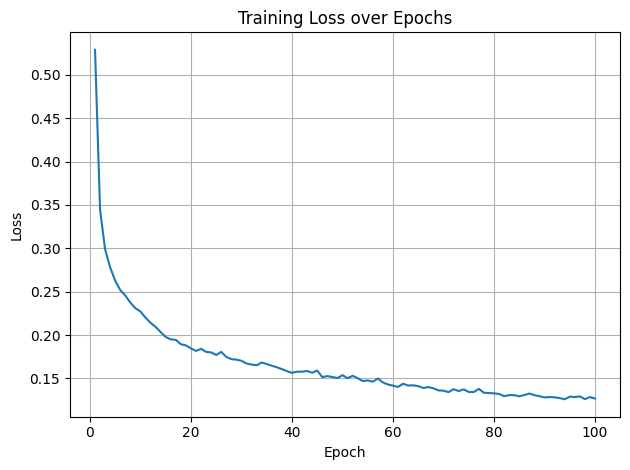

In [14]:
plt.plot(range(1, epochs + 1), loss_values, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss over Epochs")
plt.grid(True)
plt.tight_layout()
plt.show()

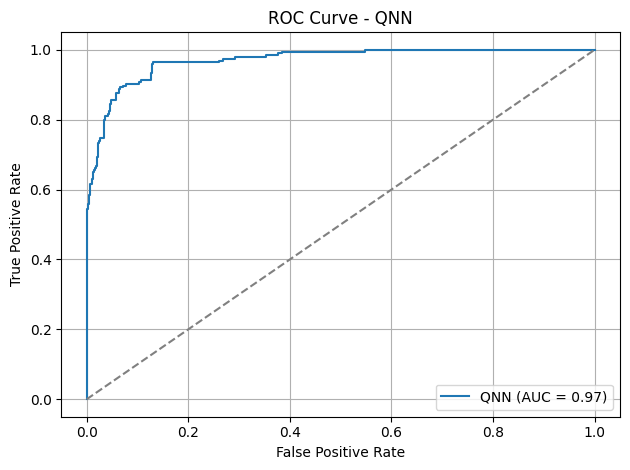

In [15]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test_100, qnn_sigmoid.numpy())
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'QNN (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - QNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
qnn_model = model

In [17]:
qnn_model = model
qsvm_preds = all_test_preds
X_meta = np.vstack([qsvm_preds, qnn_preds]).T  # shape: (n_samples, 2)
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the meta-model
meta_model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
meta_model_rf.fit(X_meta, y_test[:1000])  # match y_test slicing
ensemble_rf_preds = meta_model_rf.predict(X_meta)

print("Random Forest Meta-Model Accuracy:", accuracy_score(y_test[:1000], ensemble_rf_preds))
print("\nClassification Report (Random Forest Meta-Model):")
print(classification_report(y_test[:1000], ensemble_rf_preds))


Random Forest Meta-Model Accuracy: 0.929

Classification Report (Random Forest Meta-Model):
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       805
           1       0.84      0.78      0.81       195

    accuracy                           0.93      1000
   macro avg       0.90      0.87      0.88      1000
weighted avg       0.93      0.93      0.93      1000



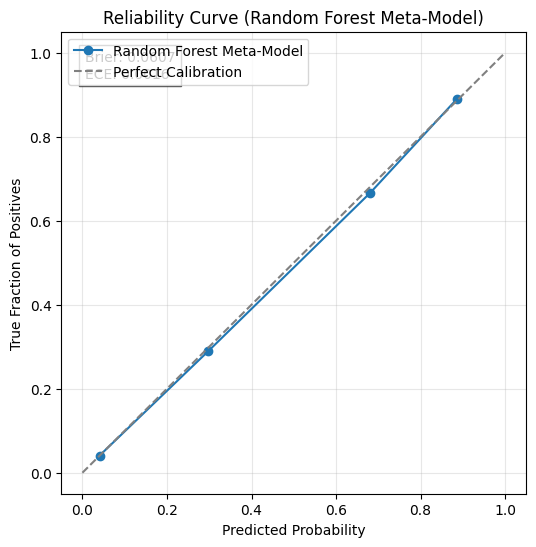

Brier Score: 0.0607
Expected Calibration Error (ECE): 0.0016


In [18]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt
import numpy as np

# --- Step 1: Predict probabilities on the same meta-data ---
meta_probs = meta_model_rf.predict_proba(X_meta)[:, 1]
meta_preds = meta_model_rf.predict(X_meta)
y_meta_test = y_test[:1000]  # for clarity

# --- Step 2: Compute reliability curve (15 bins) ---
prob_true, prob_pred = calibration_curve(y_meta_test, meta_probs, n_bins=15, strategy='uniform')

# --- Step 3: Compute Brier score ---
brier = brier_score_loss(y_meta_test, meta_probs)

# --- Step 4: Compute Expected Calibration Error (ECE) ---
def compute_ece(y_true, y_prob, n_bins=15):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    binids = np.digitize(y_prob, bins) - 1
    ece = 0.0
    for i in range(n_bins):
        bin_mask = binids == i
        if np.any(bin_mask):
            acc = np.mean(y_true[bin_mask])
            conf = np.mean(y_prob[bin_mask])
            ece += np.abs(acc - conf) * np.mean(bin_mask)
    return ece

ece = compute_ece(y_meta_test, meta_probs, n_bins=15)

# --- Step 5: Plot Reliability Curve ---
plt.figure(figsize=(6,6))
plt.plot(prob_pred, prob_true, marker='o', label='Random Forest Meta-Model')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
plt.title('Reliability Curve (Random Forest Meta-Model)')
plt.xlabel('Predicted Probability')
plt.ylabel('True Fraction of Positives')
plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.text(0.05, 0.9, f'Brier: {brier:.4f}\nECE: {ece:.4f}', transform=plt.gca().transAxes,
         bbox=dict(facecolor='white', alpha=0.7))
plt.show()

print(f"Brier Score: {brier:.4f}")
print(f"Expected Calibration Error (ECE): {ece:.4f}")


In [23]:
model = load('final_model(13).joblib')
ensemble_rf_preds = model.predict(X_meta)
print("Random Forest Meta-Model Accuracy:", accuracy_score(y_test[:1000], ensemble_rf_preds))
print("\nClassification Report (Random Forest Meta-Model):")
print(classification_report(y_test[:1000], ensemble_rf_preds))

Random Forest Meta-Model Accuracy: 0.929

Classification Report (Random Forest Meta-Model):
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       805
           1       0.84      0.78      0.81       195

    accuracy                           0.93      1000
   macro avg       0.90      0.87      0.88      1000
weighted avg       0.93      0.93      0.93      1000



In [24]:
from sklearn.metrics import f1_score

f1 = f1_score(all_test_labels, all_test_preds)

print(f"F1 Score QSVM: {f1:.4f}")

from sklearn.metrics import average_precision_score, precision_recall_curve, auc

auprc_qsvm = average_precision_score(all_test_labels, all_test_preds)

print(f"AUPRC QSVM: {auprc_qsvm:.4f}")

F1 Score QSVM: 0.7374
AUPRC QSVM: 0.6004


Min FPR: 0.0
Max FPR: 1.0


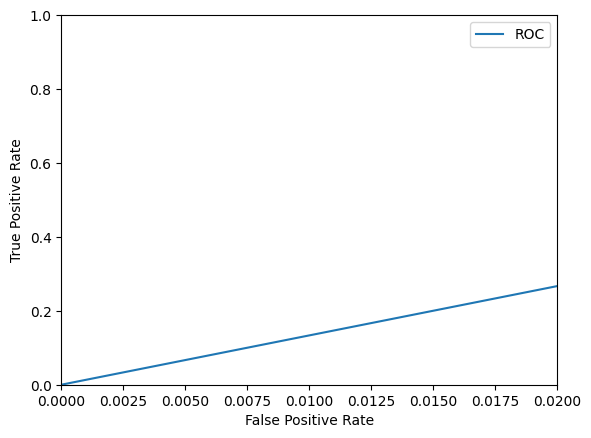

{'TPR@0.1%FPR': 0.013344663088849134, 'TPR@1.0%FPR': 0.13344663088849135}


In [25]:
from sklearn.metrics import roc_curve
def compute_tpr_at_fpr(y_true, y_score, fpr_targets=[0.001, 0.01]):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    print("Min FPR:", fpr.min())
    print("Max FPR:", fpr.max())

    results = {}
    for target in fpr_targets:
        # Always interpolate for robustness
        results[f"TPR@{target*100:.1f}%FPR"] = float(np.interp(target, fpr, tpr))

    # Plot zoomed-in ROC curve
    import matplotlib.pyplot as plt
    plt.plot(fpr, tpr, label="ROC")
    plt.xlim(0, 0.02)   # zoom in to 0–2% FPR
    plt.ylim(0, 1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

    return results


# Example
metrics = compute_tpr_at_fpr(all_test_labels, all_test_preds)
print(metrics)

F1 score QNN: 0.8107
AUPRC QNN: 0.7012
Min FPR: 0.0
Max FPR: 1.0


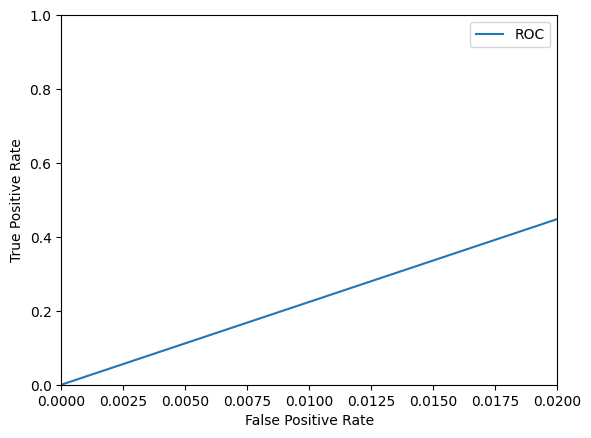

{'TPR@0.1%FPR': 0.02241025641025641, 'TPR@1.0%FPR': 0.2241025641025641}


In [26]:
f2 = f1_score(y_test_tensor, qnn_preds)

print(f"F1 score QNN: {f2:.4f}")

auprc_qsvm = average_precision_score(y_test_tensor, qnn_preds)

print(f"AUPRC QNN: {auprc_qsvm:.4f}")

metrics = compute_tpr_at_fpr(y_test_tensor, qnn_preds)
print(metrics)

F1 score RF Ensemble: 0.8107
AUPRC RF Ensemble: 0.7012
Min FPR: 0.0
Max FPR: 1.0


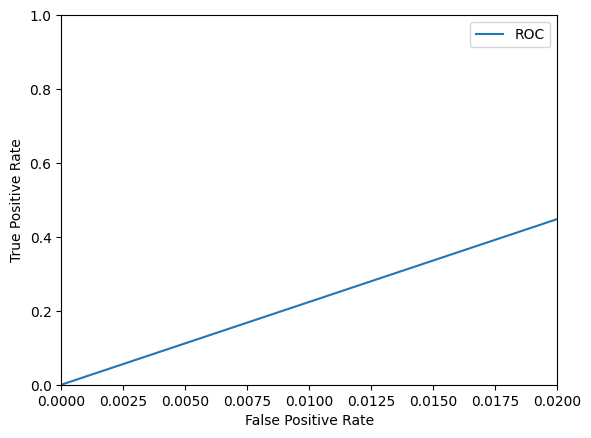

{'TPR@0.1%FPR': 0.02241025641025641, 'TPR@1.0%FPR': 0.2241025641025641}


In [27]:
f3 = f1_score(y_test[:1000], ensemble_rf_preds)

print(f"F1 score RF Ensemble: {f3:.4f}")
auprc_rf = average_precision_score(y_test[:1000], ensemble_rf_preds)

print(f"AUPRC RF Ensemble: {auprc_rf:.4f}")
metrics = compute_tpr_at_fpr(y_test[:1000], ensemble_rf_preds)
print(metrics)

In [28]:
from ptflops import get_model_complexity_info
import torch

# FLOPs for QNN
dummy_input = torch.rand(1, X_train.shape[1])  # 1 sample with correct feature size
flops, params = get_model_complexity_info(qnn_model, (X_train.shape[1],), verbose=False)

print(f"QNN FLOPs: {flops}, Params: {params}")


QNNClassifier(
  14, 6.699% Params, 14.0 Mac, 100.000% MACs, 
  (qlayer): <Quantum Torch Layer: func=qnn_circuit>
  (fc): Linear(14, 6.699% Params, 14.0 Mac, 100.000% MACs, in_features=13, out_features=1, bias=True)
)
QNN FLOPs: 14 Mac, Params: 209


In [29]:
def estimate_rf_flops(model, num_features, num_samples):
    """
    Rough estimate FLOPs for Random Forest:
    - Each decision tree: O(depth * num_samples)
    - Multiply by number of trees
    """
    avg_depth = sum(estimator.tree_.max_depth for estimator in model.estimators_) / len(model.estimators_)
    flops = len(model.estimators_) * avg_depth * num_samples * num_features
    return flops

rf_flops = estimate_rf_flops(meta_model_rf, num_features=2, num_samples=len(X_test))  # 2 features = QSVM+QNN outputs
print(f"Estimated RF FLOPs: {rf_flops}")


Estimated RF FLOPs: 1598400.0


In [30]:
def estimate_qsvm_flops(num_features, num_samples, num_batches):
    """
    Approx FLOPs for QSVM = O(N^2 * feature_map_cost)
    - num_features: features in each input vector
    - num_samples: number of training samples per batch
    - num_batches: number of batches QSVM was trained on
    """
    # Rough estimate: each kernel evaluation ~ O(num_features^2)
    feature_map_cost = num_features ** 2
    per_batch_flops = (num_samples ** 2) * feature_map_cost
    total_flops = num_batches * per_batch_flops
    return total_flops

# Example usage with your dataset
qsvm_flops = estimate_qsvm_flops(X_train.shape[1], len(X_train)//10, 10)  # since 10 batches
print(f"Estimated QSVM FLOPs: {qsvm_flops}")


Estimated QSVM FLOPs: 4315590760


In [31]:
from sklearn.metrics import accuracy_score, classification_report, f1_score, average_precision_score
from sklearn.linear_model import LogisticRegression

# Build meta features
X_meta = np.vstack([qsvm_preds, qnn_preds]).T

# Initialize and train Logistic Regression meta-model
meta_model_logreg = LogisticRegression(max_iter=500, random_state=42)
meta_model_logreg.fit(X_meta, y_test[:1000])

# Predictions
ensemble_logreg_preds = meta_model_logreg.predict(X_meta)
ensemble_logreg_probs = meta_model_logreg.predict_proba(X_meta)[:, 1]

# Evaluation
print("Logistic Regression Meta-Model Accuracy:", accuracy_score(y_test[:1000], ensemble_logreg_preds))
print("F1 Score:", f1_score(y_test[:1000], ensemble_logreg_preds))
print("AUPRC:", average_precision_score(y_test[:1000], ensemble_logreg_probs))
print("\nClassification Report (Logistic Regression Meta-Model):")
print(classification_report(y_test[:1000], ensemble_logreg_preds))


Logistic Regression Meta-Model Accuracy: 0.929
F1 Score: 0.8106666666666666
AUPRC: 0.7615857183930579

Classification Report (Logistic Regression Meta-Model):
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       805
           1       0.84      0.78      0.81       195

    accuracy                           0.93      1000
   macro avg       0.90      0.87      0.88      1000
weighted avg       0.93      0.93      0.93      1000



In [32]:
from xgboost import XGBClassifier

# Build meta features
X_meta = np.vstack([qsvm_preds, qnn_preds]).T

# Initialize and train XGBoost meta-model
meta_model_xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    use_label_encoder=False,
    eval_metric="logloss"
)
meta_model_xgb.fit(X_meta, y_test[1000:2000])

# Predictions
ensemble_xgb_preds = meta_model_xgb.predict(X_meta)
ensemble_xgb_probs = meta_model_xgb.predict_proba(X_meta)[:, 1]

# Evaluation
print("XGBoost Meta-Model Accuracy:", accuracy_score(y_test[1000:2000], ensemble_xgb_preds))
print("F1 Score:", f1_score(y_test[1000:2000], ensemble_xgb_preds))
print("AUPRC:", average_precision_score(y_test[1000:2000], ensemble_xgb_probs))
print("\nClassification Report (XGBoost Meta-Model):")
print(classification_report(y_test[1000:2000], ensemble_xgb_preds))


XGBoost Meta-Model Accuracy: 0.803
F1 Score: 0.0
AUPRC: 0.2035187256760861

Classification Report (XGBoost Meta-Model):
              precision    recall  f1-score   support

           0       0.80      1.00      0.89       803
           1       0.00      0.00      0.00       197

    accuracy                           0.80      1000
   macro avg       0.40      0.50      0.45      1000
weighted avg       0.64      0.80      0.72      1000



/home/ritvik/Code/lib/python3.12/site-packages/xgboost/training.py:183: UserWarning: [23:39:20] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precisio

In [33]:
# Meta-feature ablation (hard labels, margins, probabilities)
# Robust implementation: uses precomputed arrays if present, else computes safely.
import numpy as np
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import f1_score, roc_curve

# ---------- helpers ----------
def to_numpy(X):
    if hasattr(X, "values"):
        return X.values
    if isinstance(X, np.ndarray):
        return X
    return np.asarray(X)

def safe_qsvm_probs(qsvm_obj, X_np):
    """
    qsvm_obj can be:
      - a single sklearn-like estimator with predict_proba/decision_function
      - or an iterable/list of such estimators (per-batch)
    Returns: probability array shape (n_samples,)
    """
    probs_list = []
    if isinstance(qsvm_obj, (list, tuple, np.ndarray)):
        for i, clf in enumerate(qsvm_obj):
            try:
                p = get_probs_from_estimator(clf, X_np)
                probs_list.append(p)
            except Exception as e:
                warnings.warn(f"QSVM classifier #{i} failed: {e}. Skipping it.")
        if len(probs_list) == 0:
            raise RuntimeError("No QSVM classifier produced probabilities.")
        probs = np.mean(np.vstack(probs_list), axis=0)
        return probs
    else:
        return get_probs_from_estimator(qsvm_obj, X_np)

def get_probs_from_estimator(estimator, X_np):
    # Try predict_proba, then decision_function->sigmoid, then fallback to predict
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X_np)[:, 1]
    if hasattr(estimator, "decision_function"):
        df = estimator.decision_function(X_np)
        # map scores to [0,1] with sigmoid
        return 1.0 / (1.0 + np.exp(-df))
    # fallback: hard labels -> convert to float 0/1
    preds = estimator.predict(X_np)
    return np.asarray(preds, dtype=float)

def safe_qnn_probs(qnn_model_obj, X_np, batch_size=256):
    import torch
    qnn = qnn_model_obj
    qnn.eval()
    device = None
    try:
        device = next(qnn.parameters()).device
    except Exception:
        device = torch.device("cpu")
    X_t = torch.tensor(X_np, dtype=torch.float32).to(device)
    # If very large, do mini-batching
    probs = []
    with torch.no_grad():
        for i in range(0, X_t.shape[0], batch_size):
            xb = X_t[i : i + batch_size]
            out = qnn(xb)
            out_cpu = out.detach().cpu().numpy()
            # handle different output shapes:
            if out_cpu.ndim == 2 and out_cpu.shape[1] == 1:
                p = 1.0 / (1.0 + np.exp(-out_cpu[:, 0]))   # sigmoid of logits
            elif out_cpu.ndim == 2 and out_cpu.shape[1] > 1:
                # multiclass output: probability for positive class = softmax[:,1] if present
                exp = np.exp(out_cpu - out_cpu.max(axis=1, keepdims=True))
                soft = exp / exp.sum(axis=1, keepdims=True)
                if out_cpu.shape[1] >= 2:
                    p = soft[:, 1]
                else:
                    p = soft[:, 0]
            else:
                p = out_cpu.flatten()
            probs.append(p)
    return np.concatenate(probs, axis=0)

def compute_tpr_at_fpr(y_true, y_score, target_fpr=0.01):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return float(np.interp(target_fpr, fpr, tpr))

# ---------- obtain qsvm_probs and qnn_probs safely ----------
# Prefer precomputed arrays if available in the notebook environment
if 'qsvm_preds' in globals() and 'qnn_preds' in globals():
    qsvm_probs_all = np.asarray(qsvm_preds).astype(float).flatten()
    qnn_probs_all  = np.asarray(qnn_preds).astype(float).flatten()
    print("Using existing arrays: qsvm_preds and qnn_preds")
else:
    # else try to compute from model objects (try common variable names)
    X_np = to_numpy(X_test)   # will work for pd.DataFrame or np.ndarray
    # QSVM estimator variable: try common names
    qsvm_obj = globals().get('qsvc') or globals().get('qsvm') or globals().get('qsvc_model') or globals().get('qsvm_model')
    if qsvm_obj is None:
        raise RuntimeError("QSVM model not found in workspace and qsvm_preds not present.")
    try:
        qsvm_probs_all = safe_qsvm_probs(qsvm_obj, X_np)
    except Exception as e:
        raise RuntimeError(f"QSVM probability extraction failed: {e}")
    # QNN model variable: try common names
    qnn_obj = globals().get('qnn_model') or globals().get('model') or globals().get('qnn')
    if qnn_obj is None:
        raise RuntimeError("QNN model not found in workspace and qnn_preds not present.")
    try:
        qnn_probs_all = safe_qnn_probs(qnn_obj, X_np)
    except Exception as e:
        raise RuntimeError(f"QNN probability extraction failed: {e}")

# ---------- align lengths ----------
# Use the shortest available vector so we don't index out of range
n_available = min(len(qsvm_probs_all), len(qnn_probs_all), len(y_test))
if n_available < max(len(qsvm_probs_all), len(qnn_probs_all), len(y_test)):
    warnings.warn(f"Trimming to {n_available} samples to align all arrays (qsvm:{len(qsvm_probs_all)}, qnn:{len(qnn_probs_all)}, y_test:{len(y_test)})")

qsvm_probs = qsvm_probs_all[:n_available]
qnn_probs  = qnn_probs_all[:n_available]
y_meta_raw = np.asarray(y_test).flatten()[:n_available]

# If y is multiclass, convert to binary: 0 -> normal, everything else -> attack (1)
unique_y = np.unique(y_meta_raw)
if len(unique_y) > 2:
    warnings.warn("y_test appears multiclass; converting to binary (0 remains 0, others -> 1) for TPR@FPR computation.")
    y_meta = (y_meta_raw != 0).astype(int)
else:
    y_meta = y_meta_raw.astype(int)

# ---------- build meta-feature matrices ----------
qsvm_hard = (qsvm_probs >= 0.5).astype(int)
qnn_hard  = (qnn_probs >= 0.5).astype(int)

qsvm_margin = 2.0 * qsvm_probs - 1.0   # maps [0,1] -> [-1,1]
qnn_margin  = 2.0 * qnn_probs - 1.0

X_meta_hard   = np.vstack([qsvm_hard, qnn_hard]).T
X_meta_margin = np.vstack([qsvm_margin, qnn_margin]).T
X_meta_prob   = np.vstack([qsvm_probs, qnn_probs]).T

# ---------- consistent train/test split (same indices for all feature sets) ----------
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(sss.split(X_meta_hard, y_meta))

def evaluate_meta_features(X_meta, y_meta, train_idx, test_idx, meta_clf):
    X_train = X_meta[train_idx]; y_train = y_meta[train_idx]
    X_test_  = X_meta[test_idx];  y_test_ = y_meta[test_idx]

    meta_clf.fit(X_train, y_train)
    preds = meta_clf.predict(X_test_)
    # get probability-like scores for ROC/TPR@FPR
    if hasattr(meta_clf, "predict_proba"):
        probs = meta_clf.predict_proba(X_test_)[:, 1]
    elif hasattr(meta_clf, "decision_function"):
        probs = 1.0 / (1.0 + np.exp(-meta_clf.decision_function(X_test_)))
    else:
        probs = preds.astype(float)

    f1 = f1_score(y_test_, preds)
    tpr1 = compute_tpr_at_fpr(y_test_, probs, target_fpr=0.01)
    return {"F1": f1, "TPR@1%FPR": tpr1, "n_test": len(y_test_)}

# ---------- choose meta-learner here (e.g., Logistic Regression) ----------
# meta_learner = LogisticRegression(max_iter=500, random_state=42)
meta_learner = RandomForestClassifier(n_estimators=100, random_state=42)

# Evaluate for all three input types
results = {}
# results['hard']   = evaluate_meta_features(X_meta_hard, y_meta, train_idx, test_idx, meta_learner)
# results['margin'] = evaluate_meta_features(X_meta_margin, y_meta, train_idx, test_idx, LogisticRegression(max_iter=500, random_state=42))
# results['prob']   = evaluate_meta_features(X_meta_prob, y_meta, train_idx, test_idx, LogisticRegression(max_iter=500, random_state=42))
results['hard']   = evaluate_meta_features(X_meta_hard, y_meta, train_idx, test_idx, RandomForestClassifier(n_estimators=100, random_state=42))
results['margin'] = evaluate_meta_features(X_meta_margin, y_meta, train_idx, test_idx, RandomForestClassifier(n_estimators=100, random_state=42))
results['prob']   = evaluate_meta_features(X_meta_prob, y_meta, train_idx, test_idx, RandomForestClassifier(n_estimators=100, random_state=42))


# ---------- compute deltas ----------
delta_f1_a_b = results['margin']['F1'] - results['hard']['F1']
delta_f1_b_c = results['prob']['F1'] - results['margin']['F1']

delta_tpr_a_b = results['margin']['TPR@1%FPR'] - results['hard']['TPR@1%FPR']
delta_tpr_b_c = results['prob']['TPR@1%FPR'] - results['margin']['TPR@1%FPR']

# ---------- print nicely ----------
print("Meta-feature results (on held-out split):\n")
for k, v in results.items():
    print(f"{k.upper():6s} -> F1: {v['F1']:.4f}   TPR@1%FPR: {v['TPR@1%FPR']:.4f}   (n_test={v['n_test']})")

print("\nDeltas:")
print(f"ΔF1 (a→b): {delta_f1_a_b:.9f}")
print(f"ΔF1 (b→c): {delta_f1_b_c:.9f}")
print(f"ΔTPR@1%FPR (a→b): {delta_tpr_a_b:.9f}")
print(f"ΔTPR@1%FPR (b→c): {delta_tpr_b_c:.9f}")


Using existing arrays: qsvm_preds and qnn_preds


/tmp/ipykernel_168195/3233259402.py:118: UserWarning: Trimming to 1000 samples to align all arrays (qsvm:1000, qnn:1000, y_test:3996)
  warnings.warn(f"Trimming to {n_available} samples to align all arrays (qsvm:{len(qsvm_probs_all)}, qnn:{len(qnn_probs_all)}, y_test:{len(y_test)})")


Meta-feature results (on held-out split):

HARD   -> F1: 0.7748   TPR@1%FPR: 0.3442   (n_test=300)
MARGIN -> F1: 0.7748   TPR@1%FPR: 0.3442   (n_test=300)
PROB   -> F1: 0.7748   TPR@1%FPR: 0.3442   (n_test=300)

Deltas:
ΔF1 (a→b): 0.000000000
ΔF1 (b→c): 0.000000000
ΔTPR@1%FPR (a→b): 0.000000000
ΔTPR@1%FPR (b→c): 0.000000000


In [34]:
print("\nDeltas:")
print(f"ΔF1 (a→b): {delta_f1_a_b:.15f}")
print(f"ΔF1 (b→c): {delta_f1_b_c:.15f}")
print(f"ΔTPR@1%FPR (a→b): {delta_tpr_a_b:.15f}")
print(f"ΔTPR@1%FPR (b→c): {delta_tpr_b_c:.15f}")


Deltas:
ΔF1 (a→b): 0.000000000000000
ΔF1 (b→c): 0.000000000000000
ΔTPR@1%FPR (a→b): 0.000000000000000
ΔTPR@1%FPR (b→c): 0.000000000000000
